In [6]:
#IMPORTS
import sys
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.colors as mcolors

from joblib import dump, load

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from scipy.stats import gaussian_kde
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture


In [8]:
mods = {"pandas": pd, "numpy": np, "seaborn": sns,
        "matplotlib": getattr(plt, "matplotlib", None) or sys.modules.get("matplotlib"),
        "scikit-learn": sys.modules.get("sklearn"), "scipy": sys.modules.get("scipy"),
        "joblib": sys.modules.get("joblib")}
for n, m in mods.items(): print(f"{n:<14} {getattr(m, '__version__', 'not loaded') if m else 'not loaded'}")

pandas         2.3.2
numpy          1.24.4
seaborn        0.12.2
matplotlib     3.7.2
scikit-learn   1.7.2
scipy          1.11.1
joblib         1.2.0


In [473]:
#PLOT FUNCTION
def plot_freq(data: pd.DataFrame | pd.Series, title: str, mode: str = "genes", bins: int = 32):
    """
    mode:
      - "series": plot the 1D series you pass in
      - "genes":  distribution of per-gene means  (mean across samples; uses columns)
      - "samples": distribution of per-sample means (mean across genes; uses rows)
      - "entries": distribution of all individual values
    """
    if mode == "series":
        arr = pd.Series(data).dropna()
    elif mode == "genes":
        # columns = genes, rows = samples
        arr = (data.mean(axis=0) if isinstance(data, pd.DataFrame) else pd.Series(data)).dropna()
    elif mode == "samples":
        arr = (data.mean(axis=1) if isinstance(data, pd.DataFrame) else pd.Series(data)).dropna()
    elif mode == "entries":
        arr = pd.Series(np.asarray(data).ravel()).dropna()
    else:
        raise ValueError("mode must be one of {'series','genes','samples','entries'}")

    sns.histplot(arr, kde=True, bins=bins, color="dodgerblue", edgecolor=None)
    plt.xlabel(title)
    plt.ylabel("frequency")
    plt.tight_layout()
    plt.show()


In [474]:
transcriptomics = load('data/transcriptomics_matched.joblib')
proteomics = load('data/proteomics_matched.joblib')

In [475]:
# no nans and shape check
print(transcriptomics.T.isna().sum().sum(), transcriptomics.isna().sum().sum())
print(proteomics.T.isna().sum().sum(), proteomics.isna().sum().sum())
print(transcriptomics.shape, proteomics.shape)


0 0
0 0
(369, 51989) (369, 5113)


## Explorative plots

In [476]:
(transcriptomics == 0).sum().sum() / (transcriptomics.shape[0] * transcriptomics.shape[1])

# around half of the entries are 0

0.47357167122229993

In [477]:
(transcriptomics ** 2).mean()

genes
A1BG        12.185834
A1BG-AS1     5.088746
A1CF         1.063242
A2M          4.034295
A2M-AS1      0.242662
              ...    
ZYG11AP1     0.030074
ZYG11B       7.084674
ZYX         39.500006
ZZEF1       12.881894
ZZZ3        19.566464
Length: 51989, dtype: float64

c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


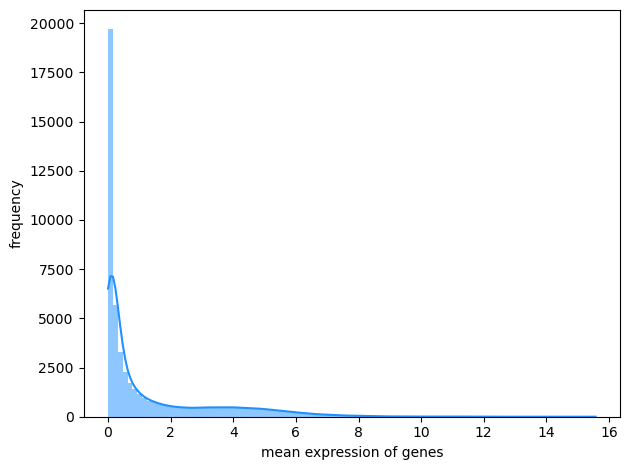

In [478]:
plot_freq((transcriptomics ** 2).mean() ** 0.5,
          title='mean expression of genes', bins=100)

c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


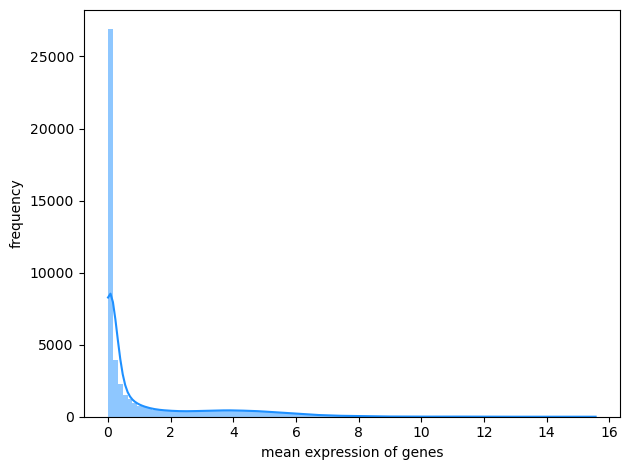

In [479]:
plot_freq(transcriptomics.mean(),
          title='mean expression of genes', bins=100)

c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


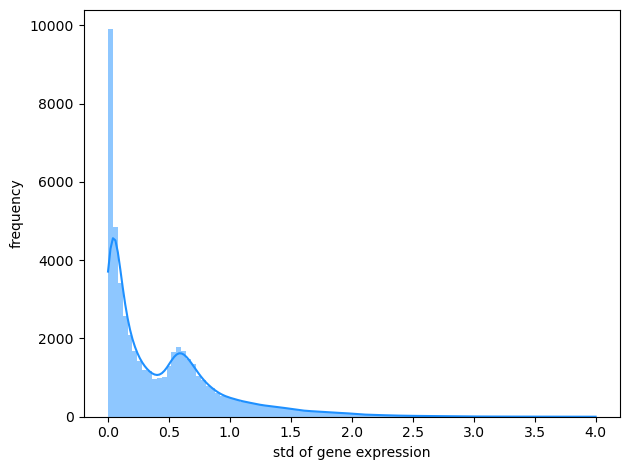

In [480]:
plot_freq(transcriptomics.std(),
          title='std of gene expression', bins=100)

c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


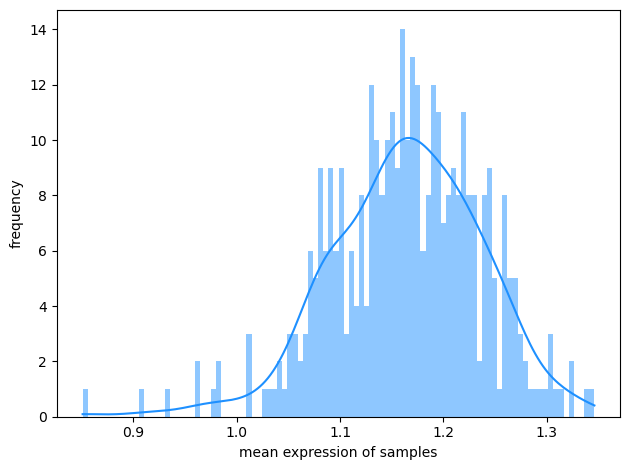

In [481]:
plot_freq(transcriptomics.T.mean(),
          title='mean expression of samples', bins=100)

In [482]:
pca = PCA(n_components=2)
pca_result = pca.fit_transform(transcriptomics.T)

pca_df = pd.DataFrame(data=pca_result, columns=['PC1', 'PC2'])

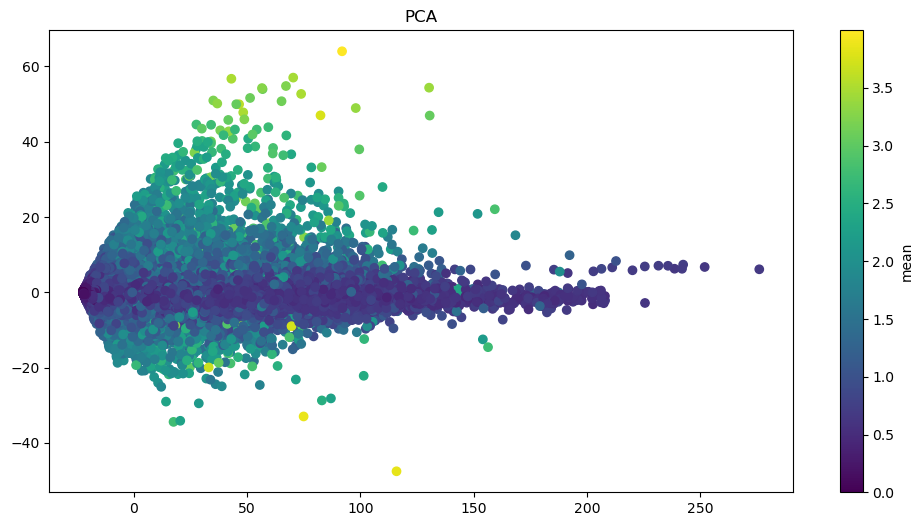

In [483]:
values = (transcriptomics != 0).sum()
values = transcriptomics.std()

norm = mcolors.Normalize(vmin=np.min(values), vmax=np.max(values))
cmap = cm.viridis

plt.figure(figsize=(12, 6))

plt.plot(1, 2)
scatter = plt.scatter(pca_df['PC1'], pca_df['PC2'], c=values, cmap=cmap, norm=norm)
plt.title('PCA')
plt.colorbar(scatter, label='mean')

In [484]:
m = len(transcriptomics)
n = len(transcriptomics.T)
m, n

(369, 51989)

c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


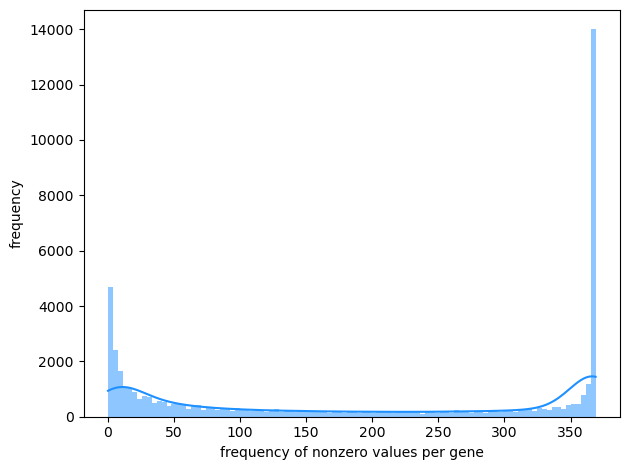

In [485]:
plot_freq((transcriptomics != 0).sum(),
          title='frequency of nonzero values per gene', bins=100)

C:\Users\hp\AppData\Local\Temp\ipykernel_33400\1981201996.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(transcriptomics.mean(), shade=True)
c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


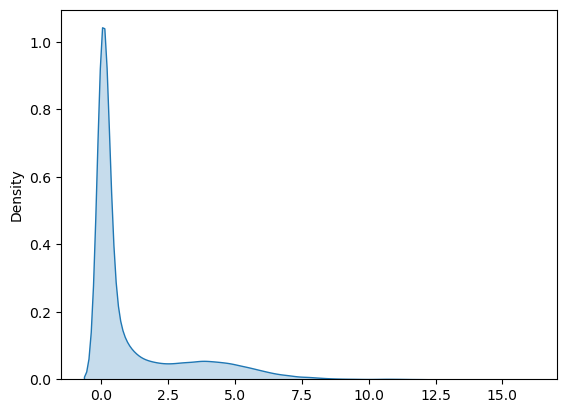

In [486]:
sns.kdeplot(transcriptomics.mean(), shade=True)
plt.show()

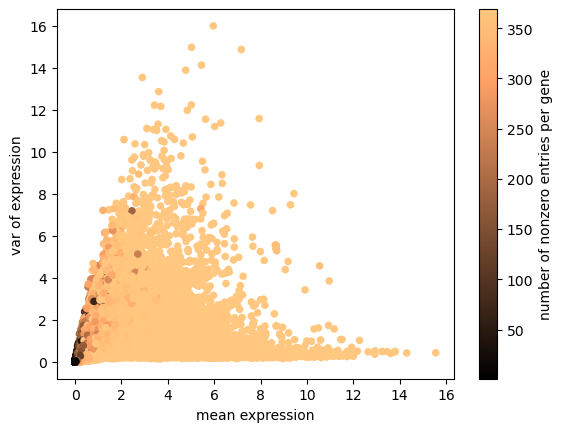

In [487]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)

x = transcriptomics.mean()[transcriptomics.std() > t]
y = transcriptomics.var()[transcriptomics.std() > t]
z = (transcriptomics != 0).sum()[transcriptomics.std() > t]

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

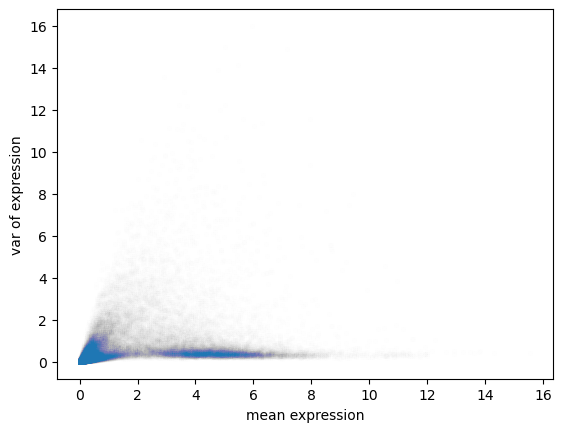

In [488]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)

x = transcriptomics.mean()[transcriptomics.std() > t]
y = transcriptomics.var()[transcriptomics.std() > t]
z = (transcriptomics != 0).sum()[transcriptomics.std() > t]
z = np.ones(len(x))

plt.scatter(x, y, s=10, alpha=0.005)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

- Reducing the opacity of dots we can see that most genes belong to one of two dense areas
- The dense area on the left is unexpressed, the one on the right is expressed
- The left peak cannot be removed by filtering out low variable genes, as the right peak would also disappear

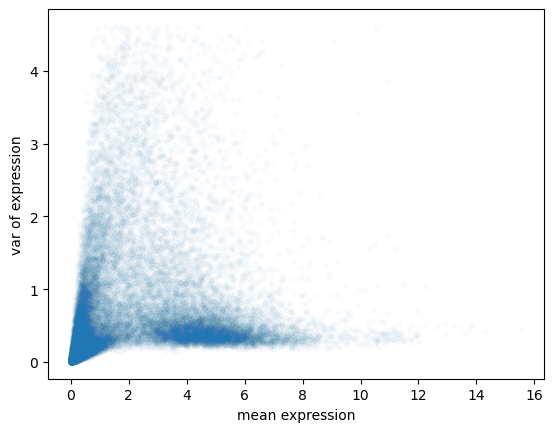

In [489]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)
u = transcriptomics.std().quantile(0.99)

x = transcriptomics.mean()[(transcriptomics.std() > t) & (transcriptomics.std() < u)]
y = transcriptomics.var()[(transcriptomics.std() > t) & (transcriptomics.std() < u)]
z = (transcriptomics != 0).sum()[(transcriptomics.std() > t) & (transcriptomics.std() < u)]
z = np.ones(len(x))

plt.scatter(x, y, s=10, alpha=0.02)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

In [490]:
len(transcriptomics.mean()[(transcriptomics.mean() >= 2) | (transcriptomics.var() >= 1)])

14590

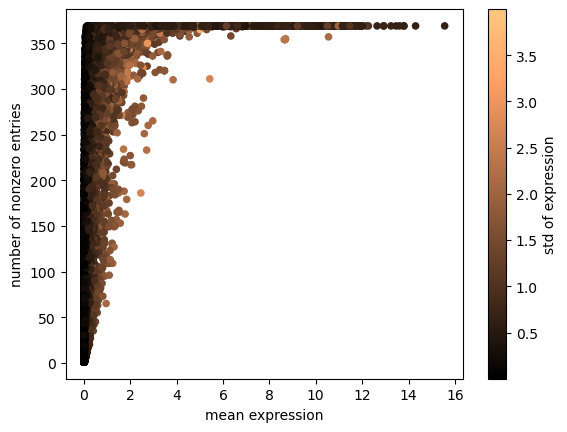

In [491]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)

x = transcriptomics.mean()[transcriptomics.std() > t]
z = transcriptomics.std()[transcriptomics.std() > t]
y = (transcriptomics != 0).sum()[transcriptomics.std() > t]

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='std of expression')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

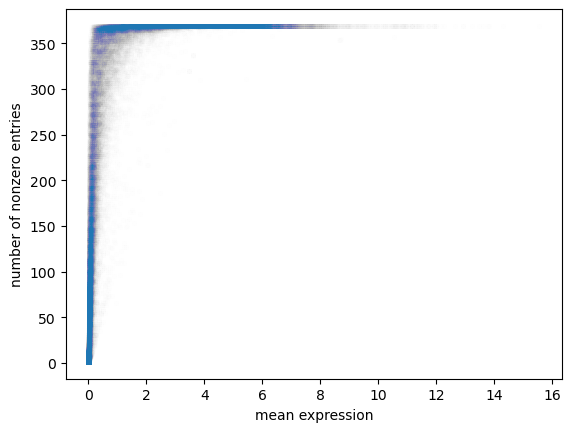

In [492]:
# remove some percentile of std
t = transcriptomics.std().quantile(0)

x = transcriptomics.mean()[transcriptomics.std() > t]
z = transcriptomics.std()[transcriptomics.std() > t]
y = (transcriptomics != 0).sum()[transcriptomics.std() > t]
z = np.ones(len(x))

plt.scatter(x, y, s=10, alpha=0.005)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

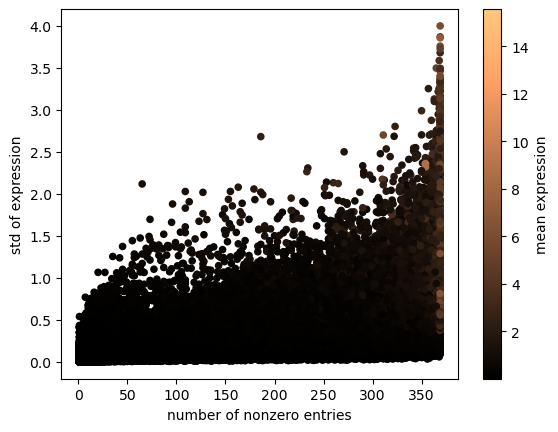

In [493]:
t = transcriptomics.std().quantile(0)

z = transcriptomics.mean()[transcriptomics.std() > t]
y = transcriptomics.std()[transcriptomics.std() > t]
x = (transcriptomics != 0).sum()[transcriptomics.std() > t]

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='mean expression')

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

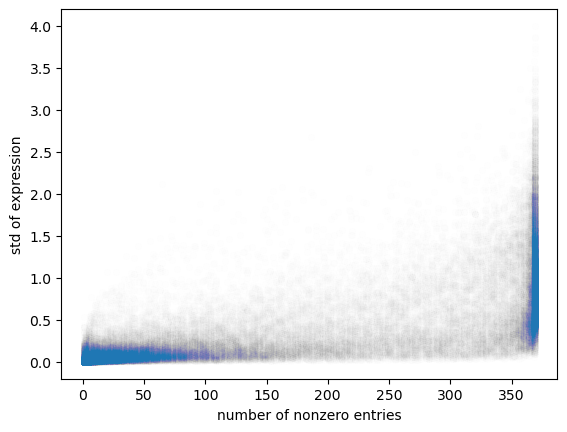

In [494]:
t = transcriptomics.std().quantile(0)

z = transcriptomics.mean()[transcriptomics.std() > t]
y = transcriptomics.std()[transcriptomics.std() > t]
x = (transcriptomics != 0).sum()[transcriptomics.std() > t]

plt.scatter(x, y, s=20, alpha=0.005)

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

## Filtered plots

c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


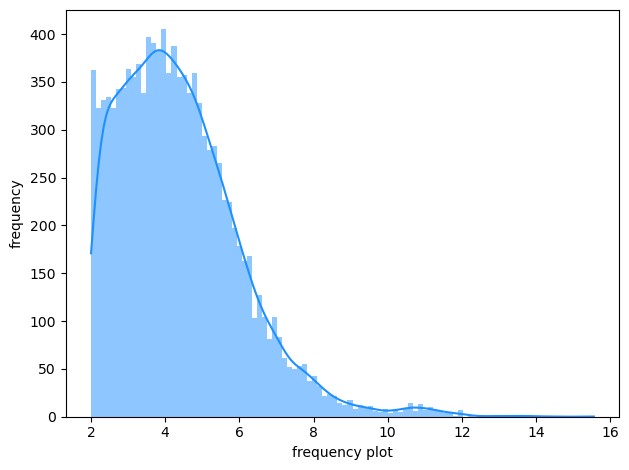

In [495]:
plot_freq(transcriptomics.mean()[transcriptomics.mean() > 2],
          title='frequency plot', bins=100)

c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


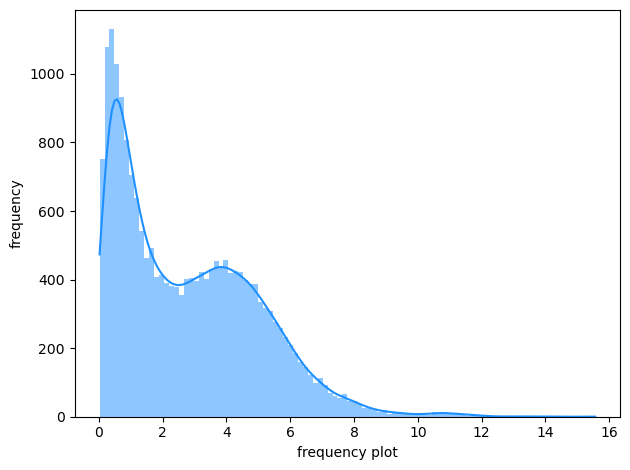

In [496]:
plot_freq(transcriptomics.mean()[(transcriptomics != 0).sum() > 300],
          title='frequency plot', bins=100)

### Mean expression filtering

In [497]:
transcriptomics.shape

(369, 51989)

In [498]:
11400/51989

0.2192771547827425

In [499]:
transcriptomics_mean_filtered = transcriptomics.T[transcriptomics.mean() > 2].T
transcriptomics_mean_filtered.shape

(369, 11400)

In [500]:
transcriptomics_mean_filtered.shape

(369, 11400)

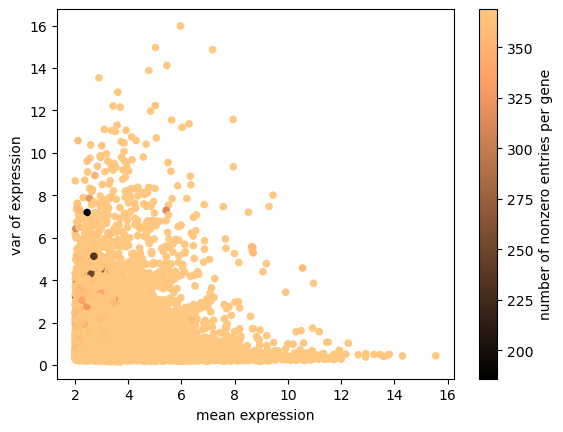

In [501]:
x = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.var()
z = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

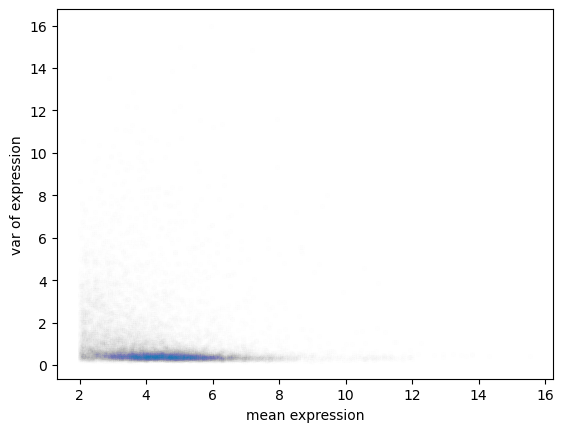

In [502]:
x = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.var()
z = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, s=10, alpha=0.005)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

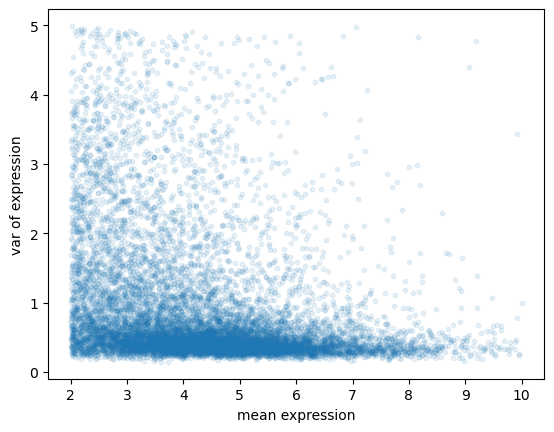

In [503]:
# zoommed plot

x = transcriptomics_mean_filtered.mean()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
y = transcriptomics_mean_filtered.var()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
z = (transcriptomics_mean_filtered != 0).sum()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]

plt.scatter(x, y, s=10, alpha=0.1)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

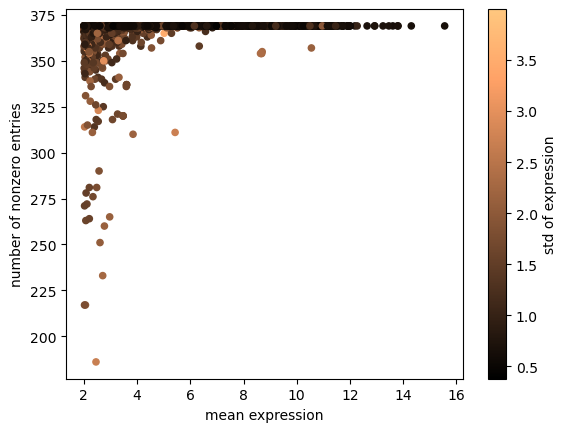

In [504]:
x = transcriptomics_mean_filtered.mean()
z = transcriptomics_mean_filtered.std()
y = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='std of expression')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

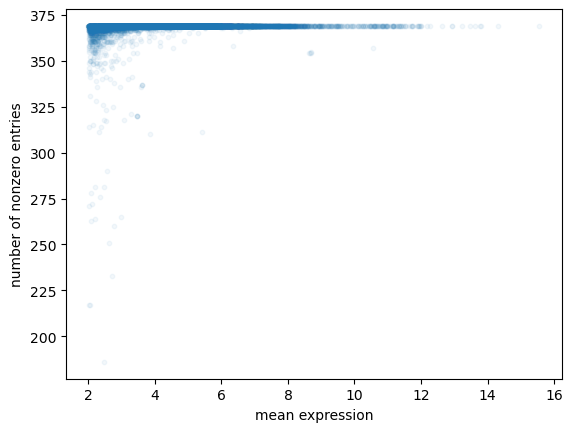

In [505]:
x = transcriptomics_mean_filtered.mean()
z = transcriptomics_mean_filtered.var()
y = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

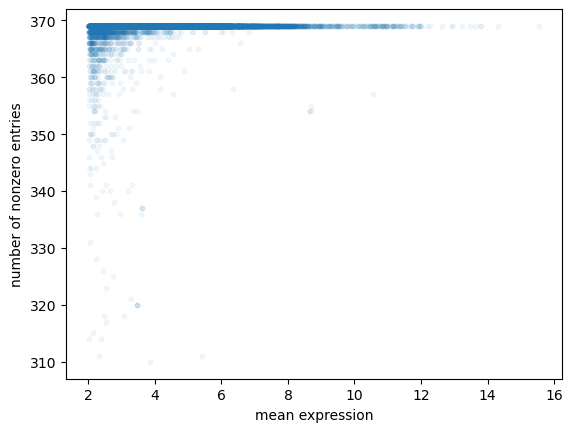

In [506]:
# zoommed

x = transcriptomics_mean_filtered.mean()[(transcriptomics_mean_filtered != 0).sum() > 300]
z = transcriptomics_mean_filtered.var()[(transcriptomics_mean_filtered != 0).sum() > 300]
y = (transcriptomics_mean_filtered != 0).sum()[(transcriptomics_mean_filtered != 0).sum() > 300]

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

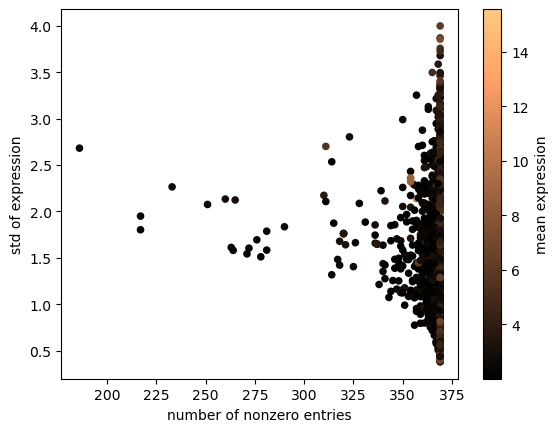

In [507]:
z = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.std()
x = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='mean expression')

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

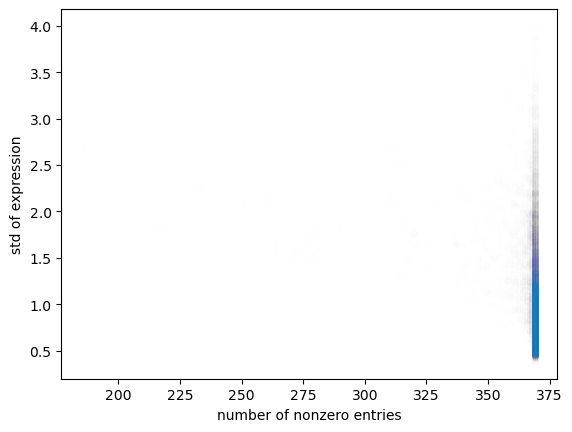

In [508]:
z = transcriptomics_mean_filtered.mean()
y = transcriptomics_mean_filtered.std()
x = (transcriptomics_mean_filtered != 0).sum()

plt.scatter(x, y, s=20, alpha=0.005)

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

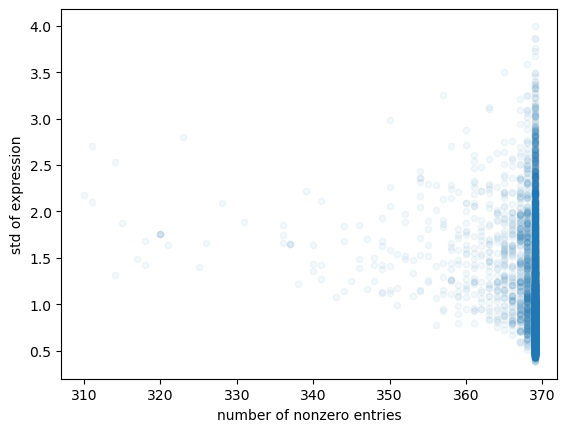

In [509]:
# zoommed

z = transcriptomics_mean_filtered.mean()[(transcriptomics_mean_filtered != 0).sum() > 300]
y = transcriptomics_mean_filtered.std()[(transcriptomics_mean_filtered != 0).sum() > 300]
x = (transcriptomics_mean_filtered != 0).sum()[(transcriptomics_mean_filtered != 0).sum() > 300]

plt.scatter(x, y, s=20, alpha=0.05)

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

In [510]:
transcriptomics_mean_filtered

genes,A1BG,A4GALT,AAAS,AACS,AADAT,AAGAB,AAK1,AAMDC,AAMP,AAR2,...,ZUP1,ZW10,ZWILCH,ZWINT,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1,ZZZ3
samples,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,2.689299,1.575312,5.311430,4.531069,2.035624,5.106432,4.461398,6.166515,7.027243,4.522307,...,3.726831,4.516015,4.139142,6.986752,3.114367,4.250962,3.250962,6.233811,3.512227,5.221490
SH4_SKIN,4.980025,0.111031,5.229972,4.095924,3.035624,5.268285,4.729553,5.007196,7.341808,4.900142,...,2.327687,3.568032,3.698218,6.113742,2.659925,4.979111,2.553361,6.644000,3.659925,4.249445
AU565_BREAST,2.518535,0.933573,6.011898,5.564378,1.996389,4.595742,3.742006,3.600508,7.496974,5.429951,...,2.981853,3.930737,4.235727,7.373909,2.049631,3.471187,2.794936,7.776828,3.814550,3.978196
KMRC1_KIDNEY,0.084064,2.903038,4.842476,3.357552,2.508429,4.767125,2.853996,6.472650,6.279657,4.550285,...,3.224966,3.661065,4.584361,6.704734,1.021480,1.475085,1.384050,5.510962,1.263034,3.416840
CAL51_BREAST,4.729553,3.751678,6.262847,3.874797,4.440288,5.307429,3.206331,5.111866,6.650908,4.541639,...,4.220330,4.365972,4.835924,7.356496,2.424922,3.884598,3.558268,6.812113,4.068671,4.939697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,0.070389,4.168321,5.244887,5.409391,2.121015,5.320846,3.534809,3.333424,6.992202,4.458776,...,4.277241,3.895303,4.865919,7.543882,0.028569,3.807355,3.247928,5.279471,4.277241,5.158660
KP4_PANCREAS,0.389567,2.163499,6.280585,4.335569,2.536053,6.667750,3.634593,5.447249,7.132474,4.223423,...,3.620586,4.280956,5.210233,6.656067,2.558268,3.754888,2.912650,6.915401,3.799087,4.475085
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,3.945795,0.042644,5.667608,3.218781,0.000000,4.857981,5.175525,3.531069,6.365448,4.372256,...,4.346248,3.949535,4.143230,7.929318,1.835924,4.955127,2.107688,5.816856,3.693766,5.030777


### Non-zeros count filtering

In [511]:
transcriptomics_nonzero_filtered = transcriptomics.T[(transcriptomics != 0).sum() > 300].T

In [512]:
transcriptomics_nonzero_filtered.shape

(369, 20653)

In [513]:
20653/51989

0.39725711208140185

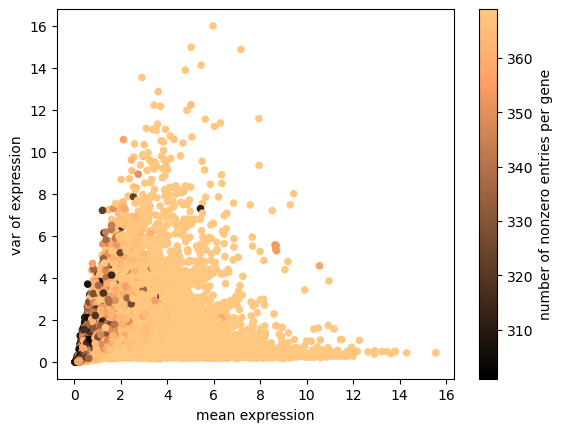

In [514]:
x = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.var()
z = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

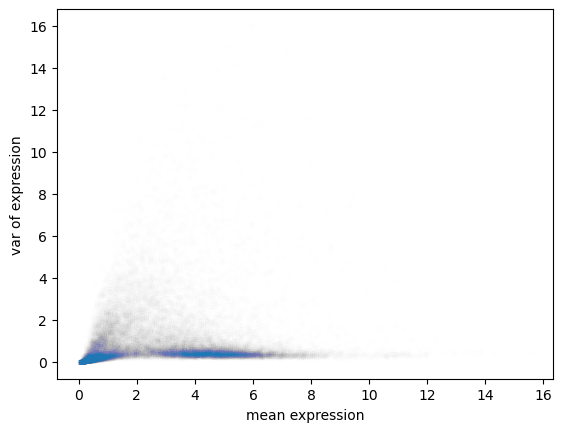

In [515]:
x = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.var()
z = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, s=10, alpha=0.005)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

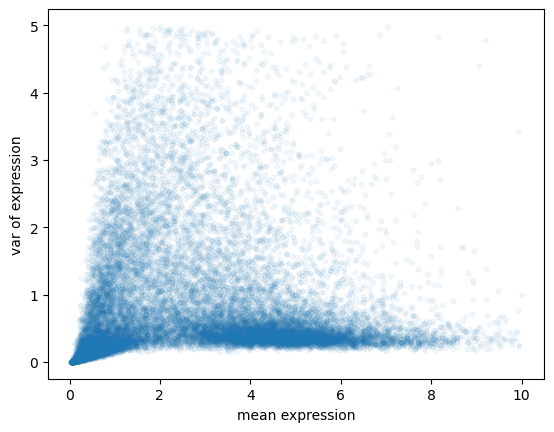

In [516]:
# zoommed plot

x = transcriptomics_nonzero_filtered.mean()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
y = transcriptomics_nonzero_filtered.var()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]
z = (transcriptomics_nonzero_filtered != 0).sum()[(transcriptomics.mean() < 10) & (transcriptomics.var() < 5)]

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

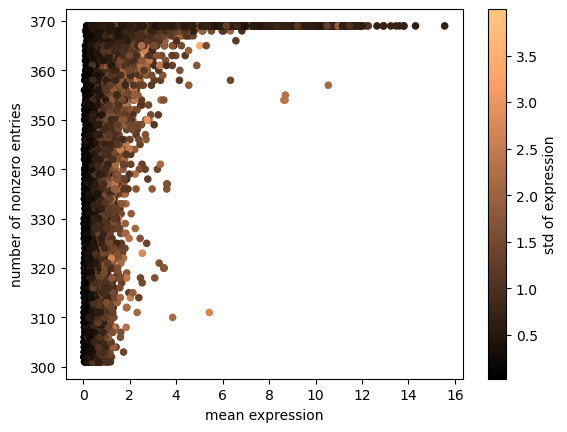

In [517]:
x = transcriptomics_nonzero_filtered.mean()
z = transcriptomics_nonzero_filtered.std()
y = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='std of expression')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

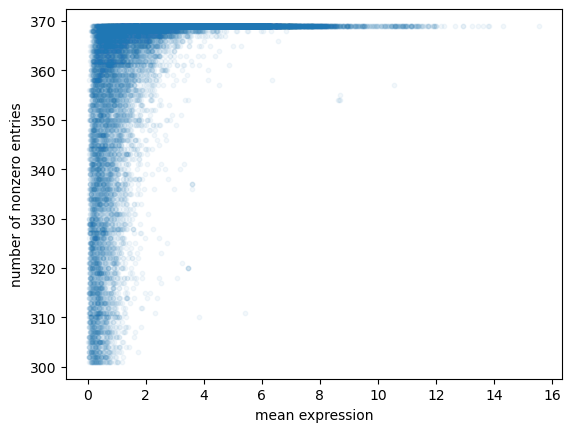

In [518]:
x = transcriptomics_nonzero_filtered.mean()
z = transcriptomics_nonzero_filtered.var()
y = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, s=10, alpha=0.05)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('number of nonzero entries')

# Show the plot
plt.show()

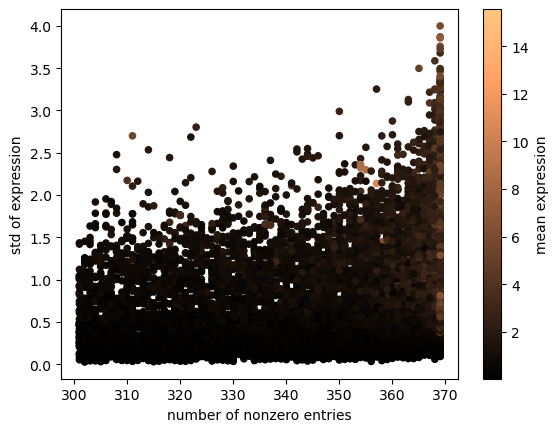

In [519]:
z = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.std()
x = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='mean expression')

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

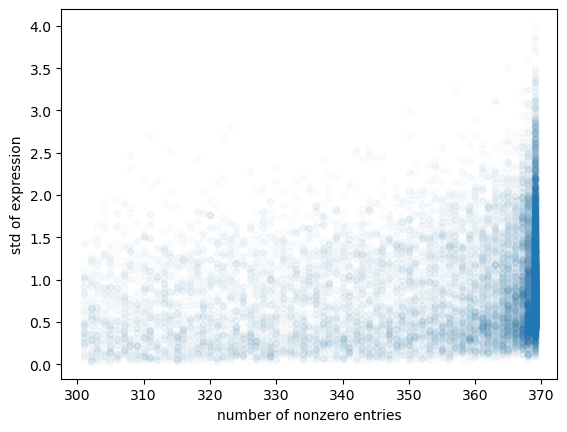

In [520]:
z = transcriptomics_nonzero_filtered.mean()
y = transcriptomics_nonzero_filtered.std()
x = (transcriptomics_nonzero_filtered != 0).sum()

plt.scatter(x, y, s=20, alpha=0.02)

# Add labels and a title
plt.xlabel('number of nonzero entries')
plt.ylabel('std of expression')

# Show the plot
plt.show()

In [521]:
transcriptomics_nonzero_filtered

genes,A1BG,A1BG-AS1,A2M,A2M-AS1,A4GALT,AAAS,AACS,AACSP1,AADAT,AAGAB,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
samples,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,2.689299,2.954196,3.329124,0.275007,1.575312,5.311430,4.531069,0.056584,2.035624,5.106432,...,4.139142,6.986752,2.192194,3.114367,4.250962,2.792855,3.250962,6.233811,3.512227,5.221490
SH4_SKIN,4.980025,3.583760,8.405099,0.887525,0.111031,5.229972,4.095924,0.070389,3.035624,5.268285,...,3.698218,6.113742,1.384050,2.659925,4.979111,0.014355,2.553361,6.644000,3.659925,4.249445
AU565_BREAST,2.518535,2.269033,1.275007,0.454176,0.933573,6.011898,5.564378,1.618239,1.996389,4.595742,...,4.235727,7.373909,0.632268,2.049631,3.471187,0.014355,2.794936,7.776828,3.814550,3.978196
KMRC1_KIDNEY,0.084064,0.070389,0.137504,0.000000,2.903038,4.842476,3.357552,0.056584,2.508429,4.767125,...,4.584361,6.704734,0.432959,1.021480,1.475085,0.485427,1.384050,5.510962,1.263034,3.416840
CAL51_BREAST,4.729553,2.807355,0.575312,0.201634,3.751678,6.262847,3.874797,0.056584,4.440288,5.307429,...,4.835924,7.356496,1.700440,2.424922,3.884598,0.084064,3.558268,6.812113,4.068671,4.939697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,0.070389,0.389567,0.028569,0.464668,4.168321,5.244887,5.409391,0.189034,2.121015,5.320846,...,4.865919,7.543882,0.014355,0.028569,3.807355,0.790772,3.247928,5.279471,4.277241,5.158660
KP4_PANCREAS,0.389567,0.632268,0.367371,0.250962,2.163499,6.280585,4.335569,0.014355,2.536053,6.667750,...,5.210233,6.656067,2.137504,2.558268,3.754888,0.042644,2.912650,6.915401,3.799087,4.475085
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,3.945795,2.185867,0.000000,0.454176,0.042644,5.667608,3.218781,0.056584,0.000000,4.857981,...,4.143230,7.929318,1.137504,1.835924,4.955127,0.056584,2.107688,5.816856,3.693766,5.030777


## Gaussian Mixtures on Means distribution

In [522]:
gmm = BayesianGaussianMixture(n_components=2,
                              random_state=18, init_params="random").fit(transcriptomics.mean().values.reshape(-1,1))

In [523]:
gmm.means_

array([[0.03445127],
       [2.37607333]])

In [524]:
gmm.covariances_

array([[[2.06248748e-03]],

       [[4.79557587e+00]]])

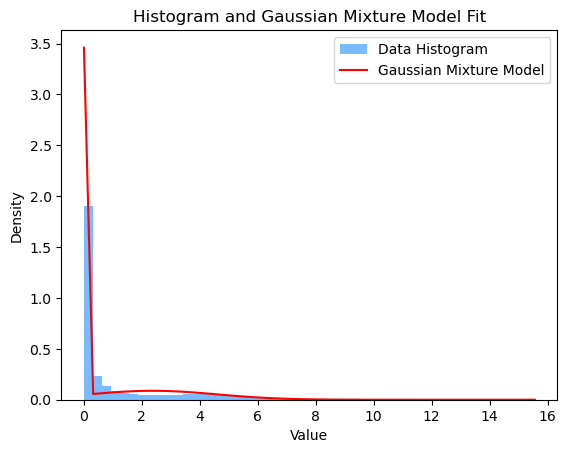

In [525]:
data = transcriptomics.mean()
X = data.values.reshape(-1, 1)

# Get the predicted labels for each data point (optional, for visualizing clusters)
labels = gmm.predict(X)

# Plot the histogram of your data (normalized to form a probability density)
plt.hist(data, bins=50, density=True, alpha=0.6, color='dodgerblue', label='Data Histogram')

# Generate the range of x values for plotting the GMM
x = np.linspace(min(data), max(data), 50).reshape(-1, 1)

# Calculate the probability density for the GMM
logprob = gmm.score_samples(x)  # Log of the probability density
pdf = np.exp(logprob)  # Convert log to the actual probability density

# Plot the Gaussian Mixture Model on top of the histogram
plt.plot(x, pdf, color='r', label='Gaussian Mixture Model')

# Add labels and a legend
plt.legend()
plt.title('Histogram and Gaussian Mixture Model Fit')
plt.xlabel('Value')
plt.ylabel('Density')
plt.show()

## Gaussian Mixtures on the Mean-Variance plane

In [526]:
arr = np.concatenate((transcriptomics.mean().values.reshape(-1,1), transcriptomics.std().values.reshape(-1,1)), axis=1)
gmm = BayesianGaussianMixture(n_components=2,
                              random_state=18, init_params="random").fit(arr)

In [527]:
gmm.means_

array([[2.33359615, 0.81614554],
       [0.03286965, 0.09874958]])

In [528]:
gmm.covariances_

array([[[4.79895724e+00, 1.46079380e-01],
        [1.46079380e-01, 2.19521458e-01]],

       [[2.01786364e-03, 3.39419837e-03],
        [3.39419837e-03, 9.78200959e-03]]])

In [529]:
arr.transpose()[0]

array([2.82520099, 1.83142183, 0.32755518, ..., 6.15178639, 3.54094815,
       4.38776499])

## KDE Local Minimum Filtering

c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


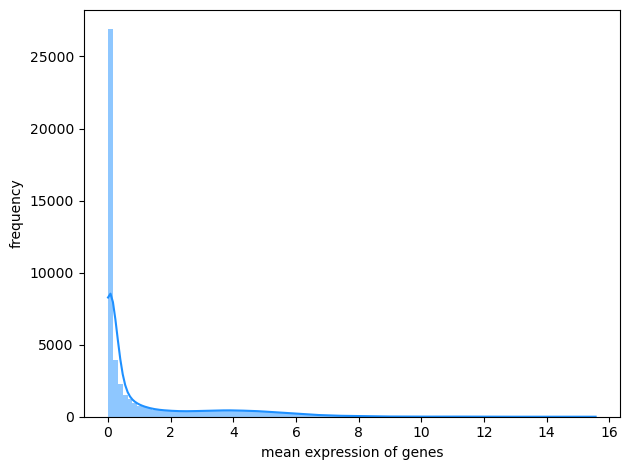

In [530]:
plot_freq(transcriptomics.mean(),
          title='mean expression of genes', bins=100)

In [531]:
data = transcriptomics.mean()

kde = gaussian_kde(data)

x_eval = np.linspace(data.min(), data.max(), 1000)
kde_vals = kde(x_eval)

mean_threshold = None

for i in range(1, len(kde_vals) - 1):
    if kde_vals[i - 1] > kde_vals[i] < kde_vals[i + 1]:
        local_min_x = x_eval[i]
        local_min_y = kde_vals[i]
        print(f"Local minimum at x = {local_min_x:.4f}, KDE = {local_min_y:.4f}")
        if mean_threshold == None:
            mean_threshold = local_min_x

Local minimum at x = 2.4919, KDE = 0.0472
Local minimum at x = 9.9833, KDE = 0.0009
Local minimum at x = 12.5843, KDE = 0.0001
Local minimum at x = 13.2073, KDE = 0.0001
Local minimum at x = 14.9360, KDE = 0.0000


c:\Users\hp\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


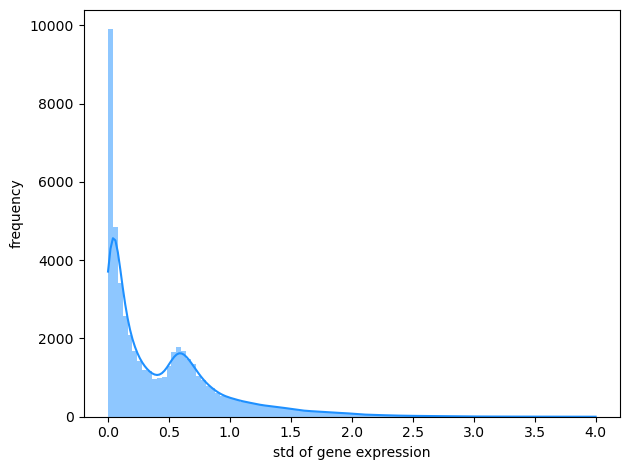

In [532]:
plot_freq(transcriptomics.std(),
          title='std of gene expression', bins=100)

In [545]:
data = transcriptomics.std()

kde = gaussian_kde(data)

x_eval = np.linspace(data.min(), data.max(), 1000)
kde_vals = kde(x_eval)

std_threshold = None

for i in range(1, len(kde_vals) - 1):
    if kde_vals[i - 1] > kde_vals[i] < kde_vals[i + 1]:
        local_min_x = x_eval[i]
        local_min_y = kde_vals[i]
        print(f"Local minimum at x = {local_min_x:.4f}, KDE = {local_min_y:.4f}")
        if std_threshold == None:
            std_threshold = local_min_x
        print(mean_threshold, std_threshold)

Local minimum at x = 0.4043, KDE = 0.5131
2.4919372332230365 0.40425836678523625
Local minimum at x = 2.9859, KDE = 0.0026
2.4919372332230365 0.40425836678523625
Local minimum at x = 3.6223, KDE = 0.0003
2.4919372332230365 0.40425836678523625
Local minimum at x = 3.8184, KDE = 0.0003
2.4919372332230365 0.40425836678523625


In [546]:
mean_threshold, std_threshold

(2.4919372332230365, 0.40425836678523625)

In [535]:
transcriptomics_kde_filtered = transcriptomics.T[(transcriptomics.mean() >= mean_threshold) |
                                                 (transcriptomics.std() >= std_threshold)].T

In [536]:
transcriptomics.shape

(369, 51989)

In [537]:
transcriptomics_kde_filtered.shape

(369, 22614)

Before filtering:

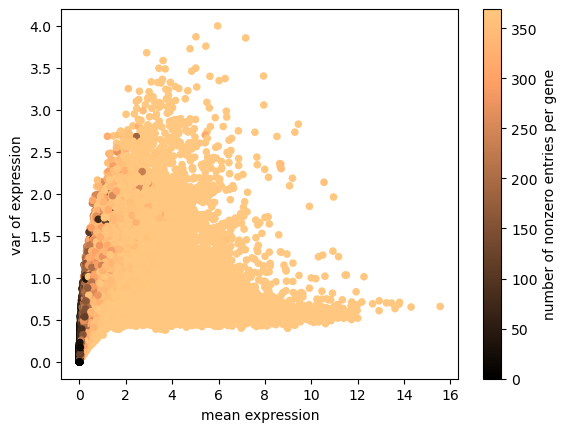

In [538]:
x = transcriptomics.mean()
y = transcriptomics.std()
z = (transcriptomics != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

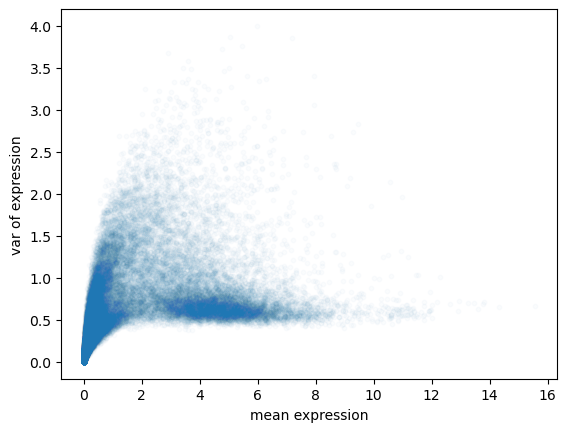

In [539]:
x = transcriptomics.mean()
y = transcriptomics.std()

plt.scatter(x, y, s=10, alpha=0.02)

plt.xlabel('mean expression')
plt.ylabel('var of expression')

plt.show()

After filtering

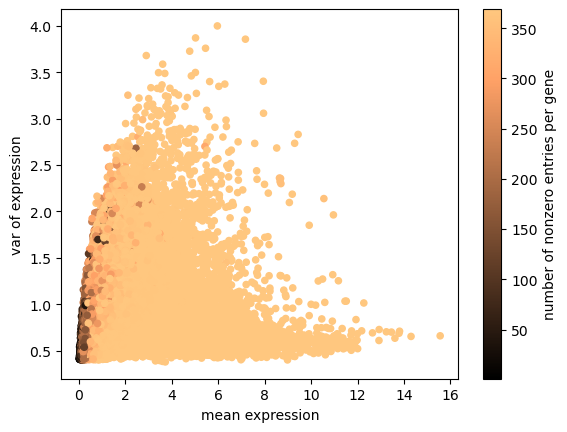

In [540]:
x = transcriptomics_kde_filtered.mean()
y = transcriptomics_kde_filtered.std()
z = (transcriptomics_kde_filtered != 0).sum()

plt.scatter(x, y, c=z, cmap='copper', s=20, alpha=1)

# Add color bar to show the mapping of z to colors
plt.colorbar(label='number of nonzero entries per gene')

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

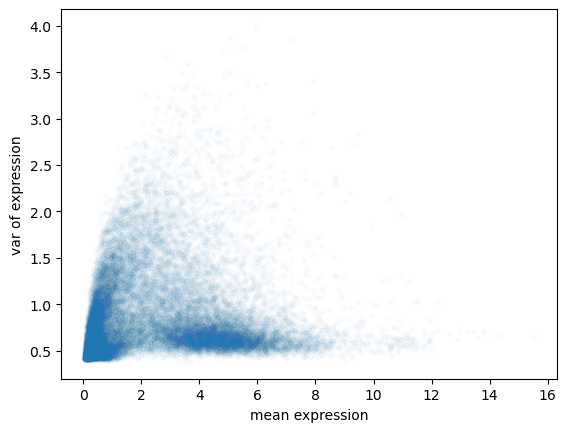

In [541]:
x = transcriptomics_kde_filtered.mean()
y = transcriptomics_kde_filtered.std()

plt.scatter(x, y, s=10, alpha=0.02)

# Add labels and a title
plt.xlabel('mean expression')
plt.ylabel('var of expression')

# Show the plot
plt.show()

In [542]:
transcriptomics_kde_filtered

genes,A1BG,A1BG-AS1,A1CF,A2M,A2ML1,A4GALT,AAAS,AACS,AACSP1,AADAC,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
samples,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,2.689299,2.954196,0.014355,3.329124,0.443607,1.575312,5.311430,4.531069,0.056584,0.124328,...,4.139142,6.986752,2.192194,3.114367,4.250962,2.792855,3.250962,6.233811,3.512227,5.221490
SH4_SKIN,4.980025,3.583760,0.000000,8.405099,0.000000,0.111031,5.229972,4.095924,0.070389,0.014355,...,3.698218,6.113742,1.384050,2.659925,4.979111,0.014355,2.553361,6.644000,3.659925,4.249445
AU565_BREAST,2.518535,2.269033,0.014355,1.275007,2.451541,0.933573,6.011898,5.564378,1.618239,0.250962,...,4.235727,7.373909,0.632268,2.049631,3.471187,0.014355,2.794936,7.776828,3.814550,3.978196
KMRC1_KIDNEY,0.084064,0.070389,0.000000,0.137504,0.000000,2.903038,4.842476,3.357552,0.056584,0.124328,...,4.584361,6.704734,0.432959,1.021480,1.475085,0.485427,1.384050,5.510962,1.263034,3.416840
CAL51_BREAST,4.729553,2.807355,0.014355,0.575312,0.713696,3.751678,6.262847,3.874797,0.056584,0.070389,...,4.835924,7.356496,1.700440,2.424922,3.884598,0.084064,3.558268,6.812113,4.068671,4.939697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,0.070389,0.389567,0.028569,0.028569,0.263034,4.168321,5.244887,5.409391,0.189034,2.446256,...,4.865919,7.543882,0.014355,0.028569,3.807355,0.790772,3.247928,5.279471,4.277241,5.158660
KP4_PANCREAS,0.389567,0.632268,0.042644,0.367371,0.150560,2.163499,6.280585,4.335569,0.014355,4.980939,...,5.210233,6.656067,2.137504,2.558268,3.754888,0.042644,2.912650,6.915401,3.799087,4.475085
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,3.945795,2.185867,0.014355,0.000000,0.070389,0.042644,5.667608,3.218781,0.056584,0.000000,...,4.143230,7.929318,1.137504,1.835924,4.955127,0.056584,2.107688,5.816856,3.693766,5.030777


In [543]:
dump(transcriptomics_kde_filtered, 'data/transcriptomics_filtered.joblib')

['data/transcriptomics_filtered.joblib']